# AgroMind v3 — Large-scale real Indian data: does the recommender hold up on Government records?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ravixalgorithm/agromind/blob/main/notebooks/AgroMind_v3_LargeScale.ipynb)

**Context.** `AgroMind_v2_Research.ipynb` showed two things. The v2 model is accurate inside its three training sources (94.3 % 5-fold accuracy). It does **not** transfer to a source it has not seen (7–13 % leave-one-source-out), because those sources disagree with one another and two of them behave like near-lookup tables. v3 therefore replaces them with real records: Government of India district-wise, season-wise crop production statistics, taken directly from the official DES portal data.desagri.gov.in (APY, 1997-98 to 2022-23) [38], joined per district with NASA POWER climate [29] and ISRIC SoilGrids soil [27]. The dataset is built by `backend/scripts/build_large_dataset.py` and documented in `docs/research/DATASET.md`.

**Contents.** 1. Data overview · 2. Task and metrics · 3. Model comparison, leave-districts-out · 4. Leave-states-out · 5. Leave-years-out · 6. Soil subset · 7. Summary.

All numbers below are computed in this notebook. Headline numbers are added under the `v3` key of `docs/research/results.json`, and figures are saved to `docs/research/figures/`.

In [1]:
import importlib.util, subprocess, sys, urllib.request
from pathlib import Path

for pkg in ("seaborn",):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

RAW = "https://raw.githubusercontent.com/ravixalgorithm/agromind/main/"
DATA = "backend/data/large/agromind_india_large.csv.gz"
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / DATA).exists()), None)
if ROOT is None:
    ROOT = Path.cwd() / "agromind"
    (ROOT / DATA).parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(RAW + DATA, ROOT / DATA)
    print("downloaded", RAW + DATA)
else:
    print("using local checkout", ROOT)
OUT = ROOT / "docs/research"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

using local checkout /Users/originkit/.config/baton/worktrees/agromind-334992/claude-1


In [2]:
import json, platform, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
T0 = time.time()
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#b8b7b0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
})
V3 = {"figures": []}

def save(fig, name, caption):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    V3["figures"].append({"file": f"figures/{name}", "caption": caption})
    plt.show()

def r4(x):
    return round(float(x), 4)

def pct(a):
    return f"{100 * np.mean(a):.2f}% ± {100 * np.std(a):.2f}%"

def folds_pct(a):
    return "[" + ", ".join(f"{100 * v:.2f}" for v in a) + "] %"

print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| pandas", pd.__version__)

python 3.12.14 | sklearn 1.9.1 | pandas 3.1.1


## 1. Data overview

In [3]:
big = pd.read_csv(ROOT / DATA, low_memory=False)
print(f"rows: {len(big):,}   columns: {big.shape[1]}")
print(f"states: {big.state.nunique()}   districts (state, district): {big.groupby(['state', 'district']).ngroups}   "
      f"centroids: {big[['lat', 'lon']].drop_duplicates().shape[0]}   crop years: {big.crop_year.nunique()} "
      f"({big.crop_year.min()} … {big.crop_year.max()})   raw crops: {big.crop.nunique()}   app crops: {big.crop_slug.nunique()}")
print("\nrows per season:"); print(big.season.value_counts().to_string())
print("\nrows per state:"); print(big.state.value_counts().to_string())

rows: 400,379   columns: 31
states: 37   districts (state, district): 748   centroids: 742   crop years: 26 (1997-98 … 2022-23)   raw crops: 54   app crops: 49

rows per season:
season
Kharif        160368
Rabi          119647
Whole Year     75890
Summer         26820
Winter          9618
Autumn          8036

rows per state:
state
Uttar Pradesh                                 50460
Karnataka                                     32561
Madhya Pradesh                                32385
Bihar                                         26524
Tamil Nadu                                    23669
Rajasthan                                     22982
Assam                                         21297
Maharashtra                                   20835
Chhattisgarh                                  18843
Odisha                                        17798
Gujarat                                       16463
West Bengal                                   14243
Andhra Pradesh                            

In [4]:
print("rows per crop (top 25 of", big.crop.nunique(), "raw crops):")
print(big.crop.value_counts().head(25).to_string())
cov = {"climate_%": 100 * big[["temperature", "humidity", "rainfall"]].notna().all(1).mean(),
       "soil_any_%": 100 * big.soil_source.notna().mean(),
       "soil_soilgrids_point_%": 100 * (big.soil_source == "soilgrids_centroid").mean()}
print("\ncoverage:", {k: round(v, 2) for k, v in cov.items()})
V3["data"] = {"rows": int(len(big)), "states": int(big.state.nunique()),
              "districts": int(big.groupby(["state", "district"]).ngroups), "crop_years": int(big.crop_year.nunique()),
              "crops_raw": int(big.crop.nunique()), "crops_app": int(big.crop_slug.nunique()),
              "coverage_pct": {k: round(v, 2) for k, v in cov.items()}}

rows per crop (top 25 of 54 raw crops):
crop
Rice                     25134
Maize                    24000
Moong(Green Gram)        17903
Urad                     17297
Sesamum                  15288
Groundnut                14746
Wheat                    12885
Arhar/Tur                12658
Rapeseed &Mustard        12637
Sugarcane                12462
Onion                    12367
Potato                   12359
Gram                     12034
Jowar                    11337
Dry chillies             10066
Bajra                     9173
Peas & beans (Pulses)     8517
Sunflower                 8261
Small millets             7998
Cotton(lint)              7625
Masoor                    7436
Ragi                      6765
Linseed                   6731
Turmeric                  6729
Barley                    6675

coverage: {'climate_%': np.float64(100.0), 'soil_any_%': np.float64(99.98), 'soil_soilgrids_point_%': np.float64(99.81)}


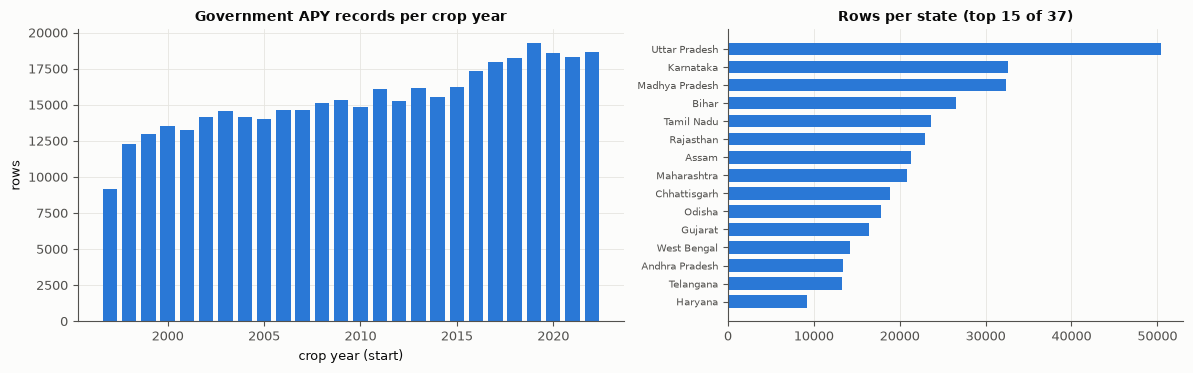

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
yr = big.groupby("year").size()
axes[0].bar(yr.index, yr.values, color=PAL[0], width=0.75)
axes[0].set_title("Government APY records per crop year"); axes[0].set_xlabel("crop year (start)"); axes[0].set_ylabel("rows")
st = big.state.value_counts().head(15)[::-1]
axes[1].barh(st.index, st.values, color=PAL[0], height=0.7)
axes[1].set_title("Rows per state (top 15 of %d)" % big.state.nunique()); axes[1].grid(axis="y", visible=False)
axes[1].tick_params(axis="y", labelsize=7)
fig.tight_layout()
save(fig, "11_v3_overview.png", "v3 large real dataset: Government APY records per crop year and per state.")

## 2. Task and metrics

**Task.** For a district, season and year, recommend the crops that do best there. The label comes from the dataset: `recommend = 1` marks the (up to) three crops with the highest within-crop yield percentile in that district–year–season (see `DATASET.md`). Each district–year–season is one **query**. Its answer is the set of recommended crops, so a single query can have one, two or three correct crops.

**Features.** Season-window climate from NASA POWER (mean temperature, mean relative humidity, total precipitation), the season, and the location (`state` one-hot, district centroid latitude/longitude). Soil is evaluated separately in §6 because SoilGrids coverage is still partial (printed above). N/P/K in v2's sense are not available at district scale, so v1/v2 models cannot be applied to these rows directly.

**Metrics** (one prediction per query):
* **hit@1**: the top-ranked crop is one of the recommended crops. This is the analogue of accuracy.
* **hit@3**: at least one of the top three is recommended. This is the analogue of the UI's top-3.
* **recall@3**: the share of the recommended crops that appear in the top three.

**Baselines.** (i) *season popularity*: rank crops by how often they are recommended in that season in the training fold. (ii) *state × season popularity*: the same within the state, falling back to (i). Baseline (ii) is strong, since it encodes what a district's neighbours usually grow, and a learned model must beat it to be worth using.

**Validation.** Climate is identical for every crop in a district–year–season, and a district repeats over 24 years. A random split would therefore place near-copies of a test query in training. All splits are grouped [18, 19]: by district (§3), by state (§4) and by time (§5).

In [6]:
lab = big[(big.recommend == 1) & big.crop_slug.notna()].copy()
lab["district_key"] = lab.state + " | " + lab.district
lab["query"] = lab.district_key + " | " + lab.year.astype(str) + " | " + lab.season
le = LabelEncoder().fit(lab.crop_slug)
lab["y"] = le.transform(lab.crop_slug)
C = len(le.classes_)
NUM = ["temperature", "humidity", "rainfall"]
GEO = ["lat", "lon"]
Q = lab.groupby("query").first()[NUM + GEO + ["season_app", "state", "district_key", "year"]]
POS = lab.groupby("query").y.apply(frozenset)
print(f"labelled rows (recommend = 1): {len(lab):,}   queries (district-year-season): {len(Q):,}   crops: {C}")
print("recommended crops per query:", POS.map(len).value_counts().sort_index().to_dict())
print("\nmost often recommended crops:"); print(lab.crop_slug.value_counts().head(15).to_string())
V3["task"] = {"labelled_rows": int(len(lab)), "queries": int(len(Q)), "crops": int(C),
              "positives_per_query": {int(k): int(v) for k, v in POS.map(len).value_counts().sort_index().items()}}

labelled rows (recommend = 1): 96,411   queries (district-year-season): 43,998   crops: 49
recommended crops per query: {1: 13484, 2: 8615, 3: 21899}

most often recommended crops:
crop_slug
rice          9737
maize         7303
blackgram     4399
wheat         4142
sugarcane     4047
mustard       4008
mungbean      3930
groundnut     3794
potato        3636
sesame        3610
pigeonpeas    3387
jowar         3050
chickpea      3046
onion         2748
chilli        2262


In [7]:
def pipe(est, num, cats, scale=False):
    parts = [("num", StandardScaler() if scale else "passthrough", num)]
    if cats:
        parts.insert(0, ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats))
    return make_pipeline(ColumnTransformer(parts), est)

def rf():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)

def rank_scores(scores, q_idx):
    """hit@1, hit@3, recall@3 of a (n_queries, C) score matrix."""
    top = np.argsort(-scores, axis=1)[:, :3]
    pos = POS.loc[q_idx].values
    h1 = np.array([t[0] in p for t, p in zip(top, pos)])
    h3 = np.array([bool(p.intersection(t)) for t, p in zip(top, pos)])
    rc = np.array([len(p.intersection(t)) / len(p) for t, p in zip(top, pos)])
    return h1, h3, rc

def model_scores(make_model, num, cats, scale, tr_q, te_q):
    tr = lab[lab["query"].isin(tr_q)]
    m = pipe(make_model(), num, cats, scale).fit(tr[num + cats], tr.y)
    S = np.zeros((len(te_q), C))
    S[:, m.classes_] = m.predict_proba(Q.loc[te_q, num + cats])
    return S

def prior_scores(by, tr_q, te_q):
    tr = lab[lab["query"].isin(tr_q)]
    season = tr.groupby(["season_app", "y"]).size().unstack(fill_value=0).reindex(columns=range(C), fill_value=0)
    S = season.reindex(Q.loc[te_q, "season_app"]).fillna(0).values.astype(float)
    S = S / np.maximum(S.sum(1, keepdims=True), 1)
    if by == "state":
        ss = tr.groupby(["state", "season_app", "y"]).size().unstack(fill_value=0).reindex(columns=range(C), fill_value=0)
        key = pd.MultiIndex.from_arrays([Q.loc[te_q, "state"], Q.loc[te_q, "season_app"]])
        L = ss.reindex(key).values
        have = ~np.isnan(L).any(1)
        L = np.nan_to_num(L)
        S[have] = L[have] / np.maximum(L[have].sum(1, keepdims=True), 1) + 1e-6 * S[have]  # season prior breaks ties
    return S

## 3. Model comparison: leave-districts-out (GroupKFold, 5 folds)

**Method.** Districts are split into five groups. Every query of a test district, in every year, is unseen in training. Feature sets: *climate + season*; *+ state*; *+ state + lat/lon*. All learned models use the last set, and the deployed v2 forest configuration (300 trees, `min_samples_leaf = 2`) [21] is also run on the other two sets as an ablation. KNN and logistic regression use standardised inputs.

In [8]:
q_ids = Q.index.values
DFOLDS = [(q_ids[a], q_ids[b]) for a, b in GroupKFold(5).split(q_ids, groups=Q.district_key.values)]
FULL = (NUM + GEO, ["season_app", "state"])
RUNS = {
    "baseline: season popularity": ("prior", "season"),
    "baseline: state x season popularity": ("prior", "state"),
    "RF: climate + season": ("model", (rf, NUM, ["season_app"], False)),
    "RF: + state": ("model", (rf, NUM, ["season_app", "state"], False)),
    "RF: + state + lat/lon": ("model", (rf, *FULL, False)),
    "ExtraTrees: + state + lat/lon": ("model", (lambda: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1), *FULL, False)),
    "KNN (k=25): + state + lat/lon": ("model", (lambda: KNeighborsClassifier(25, n_jobs=-1), *FULL, True)),
    "LogisticRegression: + state + lat/lon": ("model", (lambda: LogisticRegression(max_iter=1000), *FULL, True)),
}

def run(spec, folds):
    kind, arg = spec
    res = {"hit1": [], "hit3": [], "recall3": []}
    oof = {}
    for tr_q, te_q in folds:
        S = prior_scores(arg, tr_q, te_q) if kind == "prior" else model_scores(*arg, tr_q, te_q)
        h1, h3, rc = rank_scores(S, te_q)
        res["hit1"].append(h1.mean()); res["hit3"].append(h3.mean()); res["recall3"].append(rc.mean())
        oof.update(dict(zip(te_q, h1)))
    return res, pd.Series(oof)

dist_res = {}
for name, spec in RUNS.items():
    t = time.time()
    dist_res[name], _ = run(spec, DFOLDS)
    r = dist_res[name]
    print(f"{name}\n  hit@1 per fold {folds_pct(r['hit1'])}\n  hit@1 {pct(r['hit1'])} | hit@3 {pct(r['hit3'])} | "
          f"recall@3 {pct(r['recall3'])} | {time.time() - t:.0f}s (elapsed {time.time() - T0:.0f}s)", flush=True)
V3["leave_districts_out"] = {k: {"hit1_mean": r4(np.mean(r["hit1"])), "hit1_std": r4(np.std(r["hit1"])),
                                 "hit3_mean": r4(np.mean(r["hit3"])), "hit3_std": r4(np.std(r["hit3"])),
                                 "recall3_mean": r4(np.mean(r["recall3"]))} for k, r in dist_res.items()}
pd.DataFrame({k: {"hit@1": pct(r["hit1"]), "hit@3": pct(r["hit3"]), "recall@3": pct(r["recall3"])} for k, r in dist_res.items()}).T

baseline: season popularity
  hit@1 per fold [33.23, 33.17, 35.55, 33.37, 35.36] %
  hit@1 34.13% ± 1.08% | hit@3 61.24% ± 0.58% | recall@3 39.14% ± 0.52% | 1s (elapsed 1s)


baseline: state x season popularity
  hit@1 per fold [60.61, 64.49, 61.34, 60.61, 61.38] %
  hit@1 61.69% ± 1.44% | hit@3 88.26% ± 0.87% | recall@3 64.58% ± 1.03% | 1s (elapsed 2s)


RF: climate + season
  hit@1 per fold [52.08, 53.09, 53.57, 54.46, 52.87] %
  hit@1 53.21% ± 0.79% | hit@3 78.90% ± 0.67% | recall@3 55.95% ± 0.97% | 34s (elapsed 37s)


RF: + state
  hit@1 per fold [67.41, 68.86, 68.06, 68.16, 67.12] %
  hit@1 67.92% ± 0.61% | hit@3 90.88% ± 0.44% | recall@3 68.69% ± 0.88% | 31s (elapsed 68s)


RF: + state + lat/lon
  hit@1 per fold [71.98, 72.85, 72.50, 72.60, 71.64] %
  hit@1 72.31% ± 0.44% | hit@3 93.44% ± 0.42% | recall@3 72.54% ± 0.82% | 53s (elapsed 120s)


ExtraTrees: + state + lat/lon
  hit@1 per fold [72.32, 74.18, 73.69, 71.72, 71.39] %
  hit@1 72.66% ± 1.09% | hit@3 93.53% ± 0.44% | recall@3 72.75% ± 0.76% | 37s (elapsed 157s)


KNN (k=25): + state + lat/lon
  hit@1 per fold [69.26, 70.27, 70.30, 69.06, 69.78] %
  hit@1 69.73% ± 0.51% | hit@3 91.95% ± 0.57% | recall@3 70.26% ± 0.82% | 15s (elapsed 172s)


LogisticRegression: + state + lat/lon
  hit@1 per fold [60.51, 62.11, 59.13, 59.93, 60.95] %
  hit@1 60.53% ± 1.00% | hit@3 87.39% ± 0.96% | recall@3 63.13% ± 0.80% | 70s (elapsed 242s)


,hit@1,hit@3,recall@3
baseline: season popularity,34.13% ± 1.08%,61.24% ± 0.58%,39.14% ± 0.52%
baseline: state x season popularity,61.69% ± 1.44%,88.26% ± 0.87%,64.58% ± 1.03%
RF: climate + season,53.21% ± 0.79%,78.90% ± 0.67%,55.95% ± 0.97%
RF: + state,67.92% ± 0.61%,90.88% ± 0.44%,68.69% ± 0.88%
RF: + state + lat/lon,72.31% ± 0.44%,93.44% ± 0.42%,72.54% ± 0.82%
ExtraTrees: + state + lat/lon,72.66% ± 1.09%,93.53% ± 0.44%,72.75% ± 0.76%
KNN (k=25): + state + lat/lon,69.73% ± 0.51%,91.95% ± 0.57%,70.26% ± 0.82%
LogisticRegression: + state + lat/lon,60.53% ± 1.00%,87.39% ± 0.96%,63.13% ± 0.80%


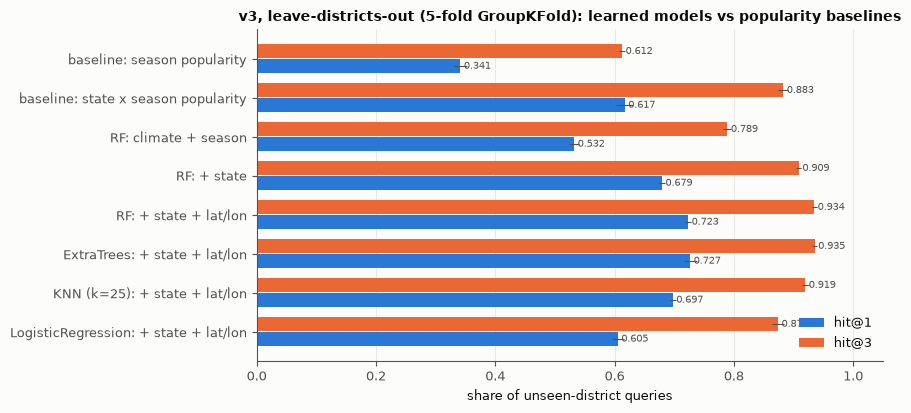

In [9]:
names = list(dist_res)[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
pos = np.arange(len(names))
for i, (key, lab_, c) in enumerate([("hit1", "hit@1", PAL[0]), ("hit3", "hit@3", PAL[1])]):
    vals = [np.mean(dist_res[n][key]) for n in names]
    ax.barh(pos + (i - 0.5) * 0.38, vals, 0.36, xerr=[np.std(dist_res[n][key]) for n in names], color=c, label=lab_,
            error_kw={"lw": 0.8, "ecolor": "#52514e"})
    for p, v in zip(pos, vals):
        ax.text(v + 0.006, p + (i - 0.5) * 0.38, f"{v:.3f}", va="center", fontsize=7, color="#52514e")
ax.set_yticks(pos, names); ax.set_xlim(0, 1.05); ax.grid(axis="y", visible=False)
ax.set_xlabel("share of unseen-district queries"); ax.legend(frameon=False, loc="lower right")
ax.set_title("v3, leave-districts-out (5-fold GroupKFold): learned models vs popularity baselines")
fig.tight_layout()
save(fig, "12_v3_leave_districts_out.png", "v3 leave-districts-out hit@1 and hit@3 of learned models and popularity baselines on real APY data.")

**Observation.** On districts never seen in training, the best models rank one of the truly recommended crops first in **72.66 % ± 1.09 %** (ExtraTrees) and **72.31 % ± 0.44 %** (Random Forest, the v2 configuration) of queries. One of them appears in the top three in **93.53 %** and **93.44 %**.

* **Against the baseline.** The strong state × season popularity baseline reaches 61.69 % / 88.26 %. The learned models therefore add about **+11 points hit@1** over "recommend what this state usually grows in this season", and the gain holds in every fold.
* **Location carries most of the signal.** Climate and season alone give 53.21 %, adding `state` gives 67.92 %, and adding latitude/longitude gives 72.31 %.
* **Other learners.** KNN (69.73 %) is close behind the forests; logistic regression (60.53 %) falls below the popularity baseline, so the relationship is clearly non-linear.

These are grouped-CV numbers on real Government records. They are lower than v2's 94 % because the task is harder and the validation is stricter, not because the model is worse.

## 4. Leave-states-out (GroupKFold by state, 5 folds)

**Method.** Whole states are held out, so the model has never seen any district of the test state. `state` cannot be encoded for an unseen state and is dropped; latitude/longitude remain, since a farm's location is known at inference time. The state × season baseline falls back to season popularity for unseen states. Results are printed per fold (with the held-out states) and per state.

In [10]:
SFOLDS = [(q_ids[a], q_ids[b]) for a, b in GroupKFold(5).split(q_ids, groups=Q.state.values)]
LSO = {"baseline: season popularity": ("prior", "season"),
       "RF: climate + season + lat/lon": ("model", (rf, NUM + GEO, ["season_app"], False))}
state_res, state_oof = {}, {}
for name, spec in LSO.items():
    state_res[name], state_oof[name] = run(spec, SFOLDS)
for k, (tr_q, te_q) in enumerate(SFOLDS):
    held = sorted(Q.loc[te_q, "state"].unique())
    print(f"fold {k + 1}: {len(te_q):,} queries from {len(held)} held-out states: {', '.join(held)}")
    for name in LSO:
        r = state_res[name]
        print(f"    {name:34s} hit@1 {100 * r['hit1'][k]:6.2f}%   hit@3 {100 * r['hit3'][k]:6.2f}%")
for name, r in state_res.items():
    print(f"{name:38s} mean hit@1 {pct(r['hit1'])}   hit@3 {pct(r['hit3'])}")
per_state = pd.DataFrame({n: s.groupby(Q.loc[s.index, "state"]).mean() for n, s in state_oof.items()})
per_state["queries"] = Q.state.value_counts()
per_state = per_state.sort_values("queries", ascending=False)
V3["leave_states_out"] = {k: {"hit1_mean": r4(np.mean(r["hit1"])), "hit1_std": r4(np.std(r["hit1"])),
                              "hit3_mean": r4(np.mean(r["hit3"]))} for k, r in state_res.items()}
V3["leave_states_out_per_state_hit1"] = {s: r4(v) for s, v in per_state["RF: climate + season + lat/lon"].items()}
print("\nhit@1 per held-out state (largest states first):")
per_state.round(4).head(20)

fold 1: 8,796 queries from 6 held-out states: Dadra and Nagar Haveli, Haryana, Jammu and Kashmir, Nagaland, Telangana, Uttar Pradesh
    baseline: season popularity        hit@1  40.17%   hit@3  61.48%
    RF: climate + season + lat/lon     hit@1  50.55%   hit@3  78.63%
fold 2: 8,806 queries from 8 held-out states: Andaman and Nicobar Islands, Bihar, Chandigarh, Jharkhand, Kerala, Manipur, Rajasthan, Tripura
    baseline: season popularity        hit@1  22.29%   hit@3  57.37%
    RF: climate + season + lat/lon     hit@1  35.23%   hit@3  63.96%
fold 3: 8,796 queries from 8 held-out states: Arunachal Pradesh, Chhattisgarh, Ladakh, Madhya Pradesh, Maharashtra, Mizoram, Punjab, The Dadra & Nagar Haveli and Daman and Diu
    baseline: season popularity        hit@1  29.87%   hit@3  53.50%
    RF: climate + season + lat/lon     hit@1  39.55%   hit@3  70.53%
fold 4: 8,796 queries from 7 held-out states: Assam, Daman and Diu, Himachal Pradesh, Karnataka, Sikkim, Tamil Nadu, Uttarakhand
    bas

,baseline: season popularity,RF: climate + season + lat/lon,queries
state,,,
Uttar Pradesh,0.3381,0.5026,5466
Bihar,0.0886,0.2541,3770
Madhya Pradesh,0.1509,0.3418,3221
Karnataka,0.2821,0.4875,2800
West Bengal,0.3878,0.2899,2687
Gujarat,0.3080,0.3666,2649
Tamil Nadu,0.5304,0.5456,2447
Maharashtra,0.3057,0.4276,2437
Rajasthan,0.2954,0.4555,2248


## 5. Leave-years-out: train on 1997–2014, test on 2015 onwards

**Method.** A recommender is used *after* the data it was trained on. We therefore train on all crop years up to 2014-15 and test on every later crop year in the data (printed below). Districts are shared between train and test here, so this measures temporal transfer alone. We report the full-feature forest and both baselines.

In [11]:
tr_q, te_q = q_ids[Q.year.values <= 2014], q_ids[Q.year.values >= 2015]
Y_LAST = int(Q.year.max())
print(f"train queries {len(tr_q):,} (1997–2014)   test queries {len(te_q):,} (2015–{Y_LAST})")
time_res = {}
for name, spec in [("baseline: season popularity", ("prior", "season")),
                   ("baseline: state x season popularity", ("prior", "state")),
                   ("RF: + state + lat/lon", ("model", (rf, *FULL, False)))]:
    r, oof = run(spec, [(tr_q, te_q)])
    by_year = oof.groupby(Q.loc[oof.index, "year"]).mean()
    time_res[name] = {"hit1": r4(r["hit1"][0]), "hit3": r4(r["hit3"][0]), "recall3": r4(r["recall3"][0]),
                      "hit1_by_year": {int(y): r4(v) for y, v in by_year.items()}}
    print(f"{name:38s} hit@1 {100 * r['hit1'][0]:.2f}%   hit@3 {100 * r['hit3'][0]:.2f}%   recall@3 {100 * r['recall3'][0]:.2f}%")
    print("    hit@1 by test year:", {y: f"{100 * v:.1f}%" for y, v in time_res[name]["hit1_by_year"].items()})
V3["leave_years_out"] = time_res

train queries 28,910 (1997–2014)   test queries 15,088 (2015–2022)


baseline: season popularity            hit@1 31.46%   hit@3 56.77%   recall@3 35.90%
    hit@1 by test year: {2015: '36.2%', 2016: '32.1%', 2017: '31.6%', 2018: '31.1%', 2019: '30.3%', 2020: '31.0%', 2021: '30.5%', 2022: '29.4%'}


baseline: state x season popularity    hit@1 55.49%   hit@3 83.68%   recall@3 59.57%
    hit@1 by test year: {2015: '61.8%', 2016: '58.6%', 2017: '58.1%', 2018: '56.4%', 2019: '54.8%', 2020: '53.0%', 2021: '52.0%', 2022: '50.0%'}


RF: + state + lat/lon                  hit@1 65.20%   hit@3 88.58%   recall@3 66.59%
    hit@1 by test year: {2015: '72.1%', 2016: '68.6%', 2017: '67.0%', 2018: '64.0%', 2019: '60.5%', 2020: '64.2%', 2021: '63.4%', 2022: '62.6%'}


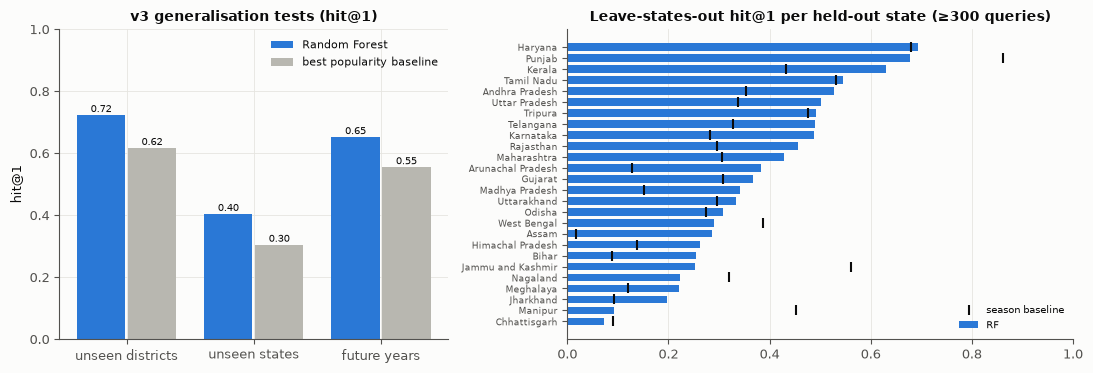

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
splits = ["unseen districts", "unseen states", "future years"]
rf_vals = [np.mean(dist_res["RF: + state + lat/lon"]["hit1"]), np.mean(state_res["RF: climate + season + lat/lon"]["hit1"]),
           time_res["RF: + state + lat/lon"]["hit1"]]
base_vals = [np.mean(dist_res["baseline: state x season popularity"]["hit1"]), np.mean(state_res["baseline: season popularity"]["hit1"]),
             time_res["baseline: state x season popularity"]["hit1"]]
pos = np.arange(3)
axes[0].bar(pos - 0.2, rf_vals, 0.38, color=PAL[0], label="Random Forest")
axes[0].bar(pos + 0.2, base_vals, 0.38, color=GREY, label="best popularity baseline")
for p, a, b in zip(pos, rf_vals, base_vals):
    axes[0].text(p - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=7); axes[0].text(p + 0.2, b + 0.01, f"{b:.2f}", ha="center", fontsize=7)
axes[0].set_xticks(pos, splits); axes[0].set_ylabel("hit@1"); axes[0].set_ylim(0, 1)
axes[0].set_title("v3 generalisation tests (hit@1)"); axes[0].legend(frameon=False, fontsize=8)
ps = per_state[per_state.queries >= 300].sort_values("RF: climate + season + lat/lon")
axes[1].barh(ps.index, ps["RF: climate + season + lat/lon"], color=PAL[0], height=0.7, label="RF")
axes[1].scatter(ps["baseline: season popularity"], ps.index, color="#0b0b0b", marker="|", s=60, zorder=3, label="season baseline")
axes[1].set_title("Leave-states-out hit@1 per held-out state (≥300 queries)"); axes[1].tick_params(axis="y", labelsize=6.5)
axes[1].grid(axis="y", visible=False); axes[1].legend(frameon=False, fontsize=7, loc="lower right"); axes[1].set_xlim(0, 1)
fig.tight_layout()
save(fig, "13_v3_generalisation.png", "v3 hit@1 for unseen districts, unseen states and future years, and per held-out state.")

**Observation.**

* **Unseen states.** Transfer to a state the model has never seen is much harder: the forest reaches **40.40 % ± 5.86 %** hit@1 and **70.45 %** hit@3, against 30.46 % / 55.44 % for the season-popularity baseline. It beats the baseline in all five folds, but only narrowly in fold 5 (34.30 % vs 32.41 %).
* **Per-state spread.** Performance varies widely between states: Haryana 0.69, Punjab 0.68 and Kerala 0.63, but Chhattisgarh only 0.07. In Punjab the popularity baseline is better still (0.86), because a rice/wheat rotation dominates there.
* **Future years.** Trained on 1997–2014 and tested on 2015–2022, the forest reaches **65.20 %** hit@1 and **88.58 %** hit@3, against 55.49 % / 83.68 % for the state × season baseline. Accuracy falls from 72.1 % (2015) to about 60–64 % in 2019–2022. The baseline decays faster (61.8 % → 50.0 %), so the model's advantage grows with time.
* **Comparison with v2.** All three grouped tests remain far above v2's 7–13 % leave-one-source-out accuracy. The decay over time argues for periodic retraining.

## 6. Soil subset

**Method.** Only queries whose district has its *own* SoilGrids profile (`soil_source == "soilgrids_centroid"`) are used. Rows that carry a state-median soil value are excluded, because a state median adds no district-level information. On these queries, the full-feature forest is compared with and without the six SoilGrids variables [27] under leave-districts-out (GroupKFold, 5 folds). In the final dataset almost every district has its own point (coverage printed in §1).

In [13]:
SOIL = ["soil_ph", "soil_n_gkg", "soil_soc_gkg", "soil_clay_pct", "soil_sand_pct", "soil_cec_cmolkg"]
soil_q = lab[lab.soil_source == "soilgrids_centroid"].groupby("query").first()  # district-point soil only (state medians excluded)
for c in SOIL:
    Q.loc[soil_q.index, c] = soil_q[c]
sq = soil_q.index.values
n_groups = soil_q.district_key.nunique()
print(f"queries with soil: {len(sq):,} from {n_groups} districts; soil source:", soil_q.soil_source.value_counts().to_dict())
soil_res = {}
if n_groups >= 5:
    folds = [(sq[a], sq[b]) for a, b in GroupKFold(5).split(sq, groups=soil_q.district_key.values)]
    for name, num in [("RF: + state + lat/lon", NUM + GEO), ("RF: + state + lat/lon + soil", NUM + GEO + SOIL)]:
        r, _ = run(("model", (rf, num, ["season_app", "state"], False)), folds)
        soil_res[name] = {"hit1_mean": r4(np.mean(r["hit1"])), "hit3_mean": r4(np.mean(r["hit3"]))}
        print(f"{name:32s} hit@1 {pct(r['hit1'])}   hit@3 {pct(r['hit3'])}")
V3["soil_subset"] = {"queries": int(len(sq)), "districts": int(n_groups),
                     "soil_source": soil_q.soil_source.value_counts().to_dict(), **soil_res}

queries with soil: 43,901 from 737 districts; soil source: {'soilgrids_centroid': 43901}


RF: + state + lat/lon            hit@1 72.26% ± 0.92%   hit@3 93.31% ± 0.66%


RF: + state + lat/lon + soil     hit@1 71.14% ± 0.44%   hit@3 92.51% ± 0.44%


**Observation.** On the 43,901 queries from 737 districts that have their own SoilGrids profile (almost the whole dataset), adding the six soil variables does **not** help: hit@1 is 71.14 % ± 0.44 % with soil against 72.26 % ± 0.92 % without, and hit@3 is 92.51 % against 93.31 %. Two explanations are consistent with this. First, a single 250 m SoilGrids point at the district centroid is a weak proxy for the soils actually farmed across a whole district. Second, the district's location (`state`, lat/lon) already captures most of what soil varies with. The live v3 model therefore does not use soil as an input.

## 7. Summary

In [14]:
best_lr = max((k for k in dist_res if not k.startswith("baseline")), key=lambda k: np.mean(dist_res[k]["hit1"]))
summary = [
    {"aspect": "Data", "v2": "67,200 rows from 3 sources that disagree on the same crop (v2 notebook §2.3)",
     "v3": f"{V3['data']['rows']:,} Government APY rows, {V3['data']['districts']} districts, {V3['data']['crop_years']} crop years"},
    {"aspect": "Labels", "v2": "crop name of each row", "v3": f"top-3 yield-percentile crops per district-year-season ({V3['task']['queries']:,} queries)"},
    {"aspect": "Validation", "v2": "random stratified 5-fold (+ LOSO)", "v3": "grouped: unseen districts, unseen states, future years"},
    {"aspect": "Unseen districts, hit@1 / hit@3", "v2": "—",
     "v3": f"{100 * V3['leave_districts_out'][best_lr]['hit1_mean']:.2f}% / {100 * V3['leave_districts_out'][best_lr]['hit3_mean']:.2f}% ({best_lr}); "
           f"baseline {100 * V3['leave_districts_out']['baseline: state x season popularity']['hit1_mean']:.2f}% / "
           f"{100 * V3['leave_districts_out']['baseline: state x season popularity']['hit3_mean']:.2f}%"},
    {"aspect": "Unseen states / regions, hit@1", "v2": "7–13% (leave-one-source-out accuracy)",
     "v3": f"{100 * V3['leave_states_out']['RF: climate + season + lat/lon']['hit1_mean']:.2f}% (baseline {100 * V3['leave_states_out']['baseline: season popularity']['hit1_mean']:.2f}%)"},
    {"aspect": f"Future years (2015–{Y_LAST}), hit@1", "v2": "not testable",
     "v3": f"{100 * V3['leave_years_out']['RF: + state + lat/lon']['hit1']:.2f}% (baseline {100 * V3['leave_years_out']['baseline: state x season popularity']['hit1']:.2f}%)"},
]
V3["summary"] = summary
for row in summary:
    print(f"{row['aspect']}\n    v2: {row['v2']}\n    v3: {row['v3']}")

Data
    v2: 67,200 rows from 3 sources that disagree on the same crop (v2 notebook §2.3)
    v3: 400,379 Government APY rows, 748 districts, 26 crop years
Labels
    v2: crop name of each row
    v3: top-3 yield-percentile crops per district-year-season (43,998 queries)
Validation
    v2: random stratified 5-fold (+ LOSO)
    v3: grouped: unseen districts, unseen states, future years
Unseen districts, hit@1 / hit@3
    v2: —
    v3: 72.66% / 93.53% (ExtraTrees: + state + lat/lon); baseline 61.69% / 88.26%
Unseen states / regions, hit@1
    v2: 7–13% (leave-one-source-out accuracy)
    v3: 40.40% (baseline 30.46%)
Future years (2015–2022), hit@1
    v2: not testable
    v3: 65.20% (baseline 55.49%)


In [15]:
V3["meta"] = {"generated_by": "notebooks/AgroMind_v3_LargeScale.ipynb", "date": time.strftime("%Y-%m-%d"),
              "python": platform.python_version(), "sklearn": sklearn.__version__, "seed": SEED,
              "runtime_seconds": round(time.time() - T0, 1),
              "doc": "hit1 = top-ranked crop is one of the recommend==1 crops of the district-year-season query; hit3 = any of the top 3 is; "
                     "recall3 = share of recommended crops in the top 3. leave_districts_out = GroupKFold(5) by state|district; "
                     "leave_states_out = GroupKFold(5) by state (state feature dropped); leave_years_out = train <=2014, test >=2015."}
res_path = OUT / "results.json"
R = json.loads(res_path.read_text()) if res_path.exists() else {}
R["v3"] = V3
R.setdefault("figures", [])
R["figures"] = [f for f in R["figures"] if "_v3_" not in f["file"]] + V3["figures"]
res_path.write_text(json.dumps(R, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("wrote v3 into", res_path, f"| total runtime {time.time() - T0:.0f}s")

wrote v3 into /Users/originkit/.config/baton/worktrees/agromind-334992/claude-1/docs/research/results.json | total runtime 389s
